In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import make_scorer, accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold
#Importing all the necessory libraries

In [3]:
df=pd.read_csv('NF-BoT-IoT_preprocessed_dataset.csv')

In [4]:
df

,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,OUT_BYTES,IN_PKTS,OUT_PKTS,TCP_FLAGS,FLOW_DURATION_MILLISECONDS,IPV4_SRC_ADDR,IPV4_DST_ADDR,label
0,0.8037,0.0008,1.0000,0.0214,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,13,18,0
1,0.7501,0.0678,0.3125,0.0000,0.9541,0.0008,0.1195,0.0663,0.1121,0.9724,13,21,4
2,0.0527,0.0012,1.0000,0.0000,0.0373,0.0367,0.2402,0.1487,0.0000,0.9723,10,27,0
3,0.0012,0.1233,0.3125,0.0287,0.0370,0.0371,0.2402,0.1487,0.0000,0.9723,8,28,0
4,0.0012,0.0012,0.3125,0.0287,0.0367,0.0000,0.2402,0.0000,0.0000,0.9723,10,27,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
600095,0.0012,0.0012,0.3125,0.0287,0.0102,0.0000,0.0667,0.0000,0.0000,0.9926,10,27,0
600096,0.0000,0.0000,0.3125,0.0000,0.0046,0.0000,0.0400,0.0000,0.0000,0.9926,11,24,0
600097,0.0056,0.0086,1.0000,0.0000,0.0003,0.0000,0.0359,0.0000,0.0000,0.9926,14,24,0
600098,0.7759,0.1355,0.3125,0.9106,0.0000,0.0000,0.0008,0.0005,0.1121,0.9930,8,8,0


In [5]:
total_nan = df.isna().sum().sum()
print("Total NaN values in the dataset:", total_nan)

Total NaN values in the dataset: 0


In [6]:
zero_counts = (df == 0).sum()
print(zero_counts)

L4_SRC_PORT                     4027
L4_DST_PORT                    11952
PROTOCOL                        3739
L7_PROTO                      416451
IN_BYTES                      597826
OUT_BYTES                     599277
IN_PKTS                       460241
OUT_PKTS                      473817
TCP_FLAGS                      38494
FLOW_DURATION_MILLISECONDS    101752
IPV4_SRC_ADDR                     25
IPV4_DST_ADDR                     23
label                          13859
dtype: int64


In [7]:

# Check if all columns in the dataframe are numerical
non_numerical_cols = df.select_dtypes(exclude=[np.number]).columns
print("Non-numerical columns:", list(non_numerical_cols))
print("All columns are numerical:", len(non_numerical_cols) == 0)

Non-numerical columns: []
All columns are numerical: True


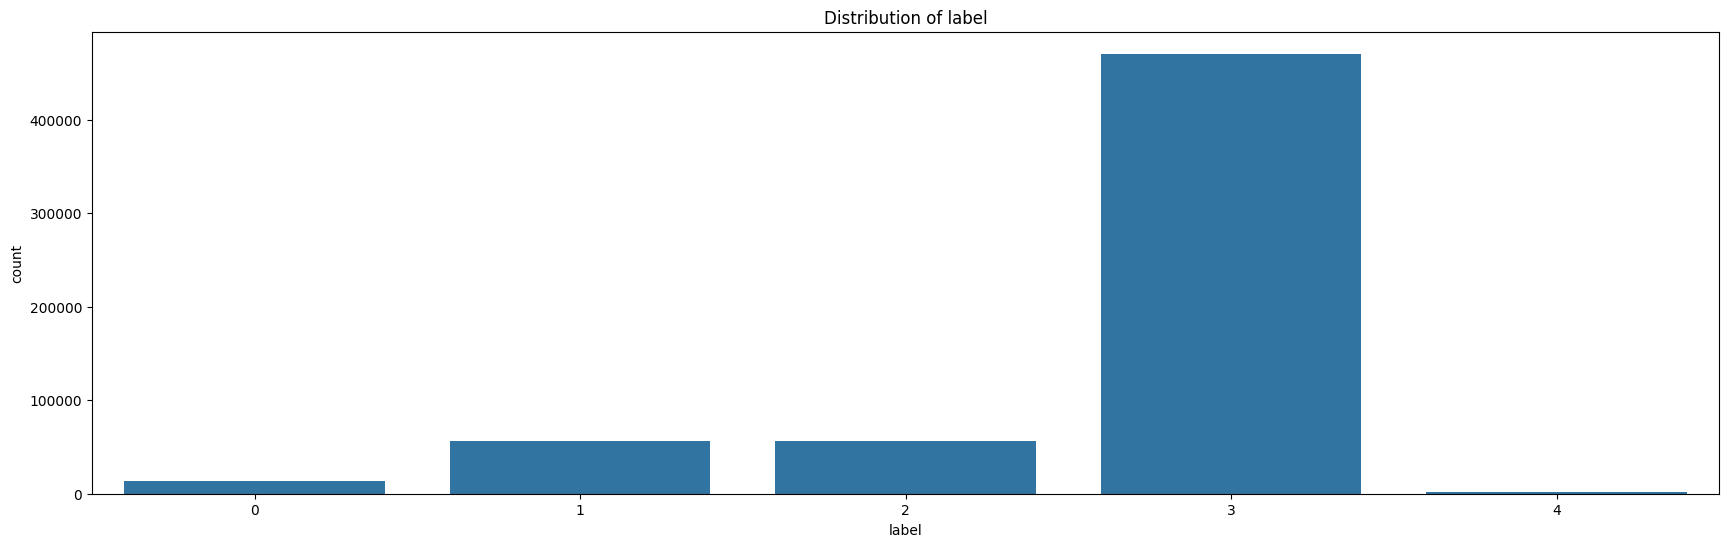

In [8]:
plt.figure(figsize=(21, 6))  
sns.countplot(data=df, x='label')
plt.title('Distribution of label')
plt.show()

In [9]:
print(df['label'].value_counts())

label
3    470655
1     56844
2     56833
0     13859
4      1909
Name: count, dtype: int64


In [10]:
X=df.drop(columns='label')
y=df['label']

In [11]:
X = X.values
y = y.values  # optional, if needed by your classifier


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from deap import base, creator, tools, algorithms
import random

# Split data for evaluation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Genetic Algorithm setup
n_features = X.shape[1]

creator.create("FitnessMax", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FitnessMax)

toolbox = base.Toolbox()
toolbox.register("attr_bool", random.randint, 0, 1)
toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_bool, n_features)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

def eval_individual(individual):
    selected_features = [i for i, bit in enumerate(individual) if bit == 1]
    if len(selected_features) == 0:
        return 0.0,
    clf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
    clf.fit(X_train[:, selected_features], y_train)
    y_pred = clf.predict(X_test[:, selected_features])
    return accuracy_score(y_test, y_pred),

toolbox.register("evaluate", eval_individual)
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutFlipBit, indpb=0.05)
toolbox.register("select", tools.selTournament, tournsize=3)

# Run Genetic Algorithm
pop = toolbox.population(n=20)
hof = tools.HallOfFame(1)
algorithms.eaSimple(pop, toolbox, cxpb=0.5, mutpb=0.2, ngen=10, halloffame=hof, verbose=True)

# Best feature subset
best_individual = hof[0]
selected_features = [i for i, bit in enumerate(best_individual) if bit == 1]
print("Selected feature indices:", selected_features)

gen	nevals
0  	20    
1  	13    
2  	13    
3  	13    
4  	10    
5  	17    
6  	7     
7  	10    
8  	16    
9  	9     
10 	10    
Selected feature indices: [1, 2, 3, 6]


In [12]:
selected_features=["L4_DST_PORT","L7_PROTO","IN_BYTES","OUT_PKTS","IPV4_SRC_ADDR","IPV4_DST_ADDR"]

In [13]:
X_selected = df[selected_features].values

In [14]:
df_selected = df[selected_features + ['label']]
print(df_selected.head())

   L4_DST_PORT  L7_PROTO  IN_BYTES  OUT_PKTS  IPV4_SRC_ADDR  IPV4_DST_ADDR  \
0       0.0008    0.0214    0.0000    0.0000             13             18   
1       0.0678    0.0000    0.9541    0.0663             13             21   
2       0.0012    0.0000    0.0373    0.1487             10             27   
3       0.1233    0.0287    0.0370    0.1487              8             28   
4       0.0012    0.0287    0.0367    0.0000             10             27   

   label  
0      0  
1      4  
2      0  
3      0  
4      0  


In [15]:
df=df_selected

In [16]:
df

,L4_DST_PORT,L7_PROTO,IN_BYTES,OUT_PKTS,IPV4_SRC_ADDR,IPV4_DST_ADDR,label
0,0.0008,0.0214,0.0000,0.0000,13,18,0
1,0.0678,0.0000,0.9541,0.0663,13,21,4
2,0.0012,0.0000,0.0373,0.1487,10,27,0
3,0.1233,0.0287,0.0370,0.1487,8,28,0
4,0.0012,0.0287,0.0367,0.0000,10,27,0
...,...,...,...,...,...,...,...
600095,0.0012,0.0287,0.0102,0.0000,10,27,0
600096,0.0000,0.0000,0.0046,0.0000,11,24,0
600097,0.0086,0.0000,0.0003,0.0000,14,24,0
600098,0.1355,0.9106,0.0000,0.0005,8,8,0


In [17]:
X=df.drop(columns='label')
y=df['label']

In [18]:
X = X.values
y = y.values  # optional, if needed by your classifier

In [19]:
from imblearn.combine import SMOTEENN

# Apply SMOTEENN to balance the dataset
smote_enn = SMOTEENN(random_state=42)
X_balanced, y_balanced = smote_enn.fit_resample(X, y)

print("Balanced class distribution:", np.bincount(y_balanced))

Balanced class distribution: [310199    262   4189 430141 343747]


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X_balanced, y_balanced,
    test_size=0.2,
    random_state=42,
    stratify=y_balanced  # ensures label distribution is preserved in both sets
)

In [21]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Step 3: Use the same scaler to transform the test data
X_test_scaled = scaler.transform(X_test)

In [22]:
y_train_balanced = y_train

In [23]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
import time

Training time: 2.5376 seconds
Prediction time: 0.0500 seconds
Accuracy: 0.9993
Precision (macro): 0.9851
Recall (macro): 0.9952
F1-score (macro): 0.9900


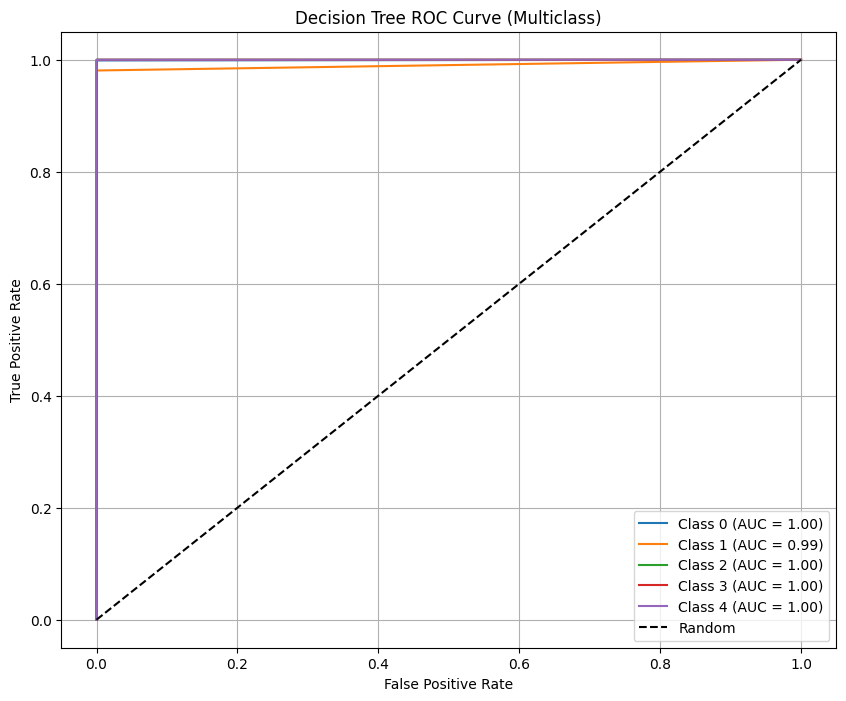

In [24]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np
import matplotlib.pyplot as plt
import time

# Define your decision tree with manually selected hyperparameters
dt = DecisionTreeClassifier(
    max_depth=80,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=42
)

# Optional: Use StratifiedKFold to ensure consistent splits, but not used here
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Train the model ONCE on the full training set
start_train = time.time()
dt.fit(X_train_scaled, y_train_balanced)
train_time = time.time() - start_train

# Predict on the test set
start_pred = time.time()
y_pred = dt.predict(X_test_scaled)
pred_time = time.time() - start_pred

# Metrics on test set
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
recall = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

print(f"Training time: {train_time:.4f} seconds")
print(f"Prediction time: {pred_time:.4f} seconds")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1-score (macro): {f1:.4f}")

# ROC Curve for multiclass
n_classes = len(np.unique(y_test))
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))
y_score = dt.predict_proba(X_test_scaled)

fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC Curve
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f'Class {i} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Decision Tree ROC Curve (Multiclass)')
plt.legend()
plt.grid(True)
plt.show()


In [36]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

benign_class = 0  # change if needed

TN = cm[benign_class, benign_class]
FP = cm[benign_class, :].sum() - TN

FAR = FP / (FP + TN)
print(FAR)


0.0019825918762088977


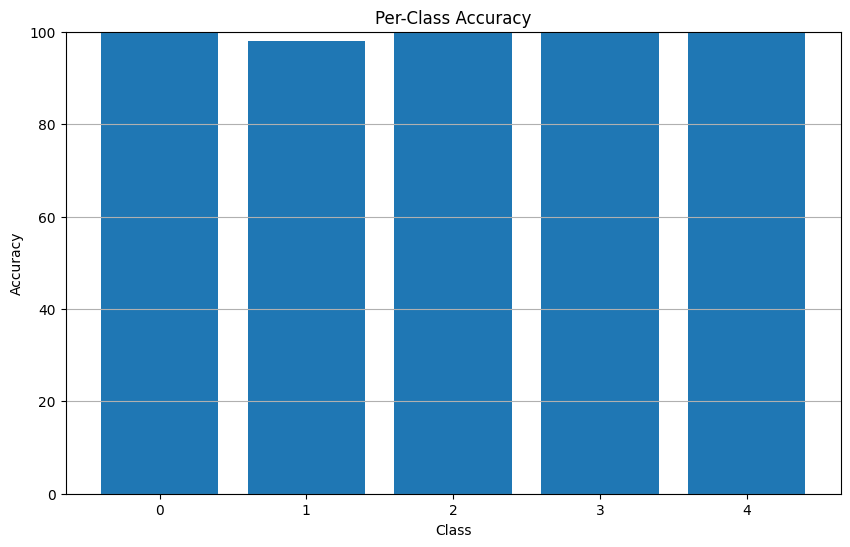

In [25]:

from sklearn.metrics import confusion_matrix

# Plot accuracy for all classes

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=np.arange(n_classes))

# Per-class accuracy: diagonal / row sum
per_class_accuracy = (cm.diagonal() / cm.sum(axis=1) )*100

plt.figure(figsize=(10, 6))
plt.bar(range(n_classes), per_class_accuracy)
plt.xlabel('Class')
plt.ylabel('Accuracy')
plt.title('Per-Class Accuracy')
plt.xticks(range(n_classes))
plt.ylim(0, 100)
plt.grid(axis='y')
plt.show()

[LightGBM] [Warning] min_data_in_leaf is set=10, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=10
[LightGBM] [Warning] lambda_l1 is set=0.1, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.1
[LightGBM] [Warning] lambda_l2 is set=1, reg_lambda=0.0 will be ignored. Current value: lambda_l2=1
[LightGBM] [Warning] min_data_in_leaf is set=10, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=10
[LightGBM] [Warning] lambda_l1 is set=0.1, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.1
[LightGBM] [Warning] lambda_l2 is set=1, reg_lambda=0.0 will be ignored. Current value: lambda_l2=1
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.024912 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1236
[LightGBM] [Info] Number of data points in the train set: 870830, number of used features:

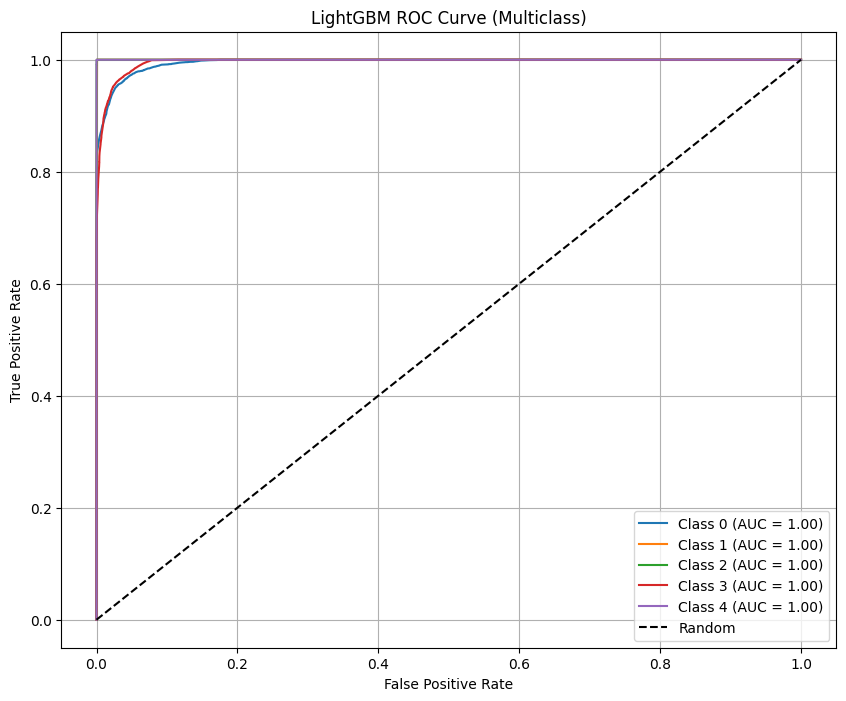

In [26]:
from lightgbm import LGBMClassifier
import lightgbm as lgb

# Manually specified number of classes
n_classes = len(np.unique(y_train_balanced))

# Binarize the true labels for ROC curve
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))

# Define LGBM model with manually chosen parameters
lgbm = LGBMClassifier(
    objective='multiclass',
    boosting_type='gbdt',
    num_class=n_classes,
    num_leaves=8,
    max_depth=16,
    min_data_in_leaf=10,
    learning_rate=0.1,
    lambda_l1=0.1,
    lambda_l2=1,
    random_state=42
)

# Train the model once
start_train = time.time()
lgbm.fit(X_train_scaled, y_train_balanced)
train_time = time.time() - start_train

# Predict on test set
start_pred = time.time()
y_pred_lgbm = lgbm.predict(X_test_scaled)
pred_time = time.time() - start_pred

# Evaluate metrics
accuracy = accuracy_score(y_test, y_pred_lgbm)
precision = precision_score(y_test, y_pred_lgbm, average='macro', zero_division=0)
recall = recall_score(y_test, y_pred_lgbm, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred_lgbm, average='macro', zero_division=0)

print(f"Training time: {train_time:.4f} seconds")
print(f"Prediction time: {pred_time:.4f} seconds")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1-score (macro): {f1:.4f}")

# ROC Curve for multiclass
y_score_lgbm = lgbm.predict_proba(X_test_scaled)
fpr_lgbm = dict()
tpr_lgbm = dict()
roc_auc_lgbm = dict()
for i in range(n_classes):
    fpr_lgbm[i], tpr_lgbm[i], _ = roc_curve(y_test_bin[:, i], y_score_lgbm[:, i])
    roc_auc_lgbm[i] = auc(fpr_lgbm[i], tpr_lgbm[i])

# Plot ROC Curve
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr_lgbm[i], tpr_lgbm[i], label=f'Class {i} (AUC = {roc_auc_lgbm[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('LightGBM ROC Curve (Multiclass)')
plt.legend()
plt.grid(True)
plt.show()


In [37]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lgbm)

benign_class = 0  # change if needed

TN = cm[benign_class, benign_class]
FP = cm[benign_class, :].sum() - TN

FAR = FP / (FP + TN)
print(FAR)


0.06428110896196003


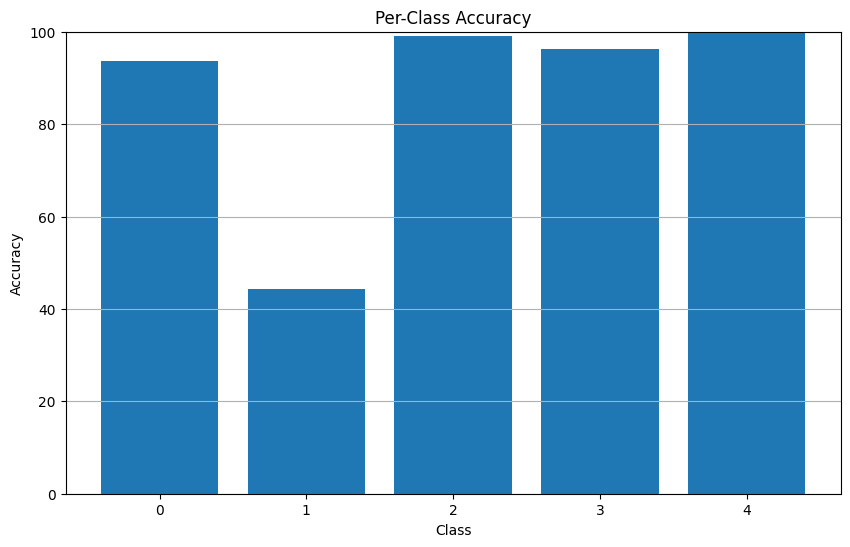

In [27]:
# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_lgbm, labels=np.arange(n_classes))

# Per-class accuracy: diagonal / row sum
per_class_accuracy = (cm.diagonal() / cm.sum(axis=1) )*100

plt.figure(figsize=(10, 6))
plt.bar(range(n_classes), per_class_accuracy)
plt.xlabel('Class')
plt.ylabel('Accuracy')
plt.title('Per-Class Accuracy')
plt.xticks(range(n_classes))
plt.ylim(0, 100)
plt.grid(axis='y')
plt.show()

Training time: 3.4426 seconds
Prediction time: 259.5967 seconds
Accuracy: 0.9903
Precision (macro): 0.9741
Recall (macro): 0.9657
F1-score (macro): 0.9698


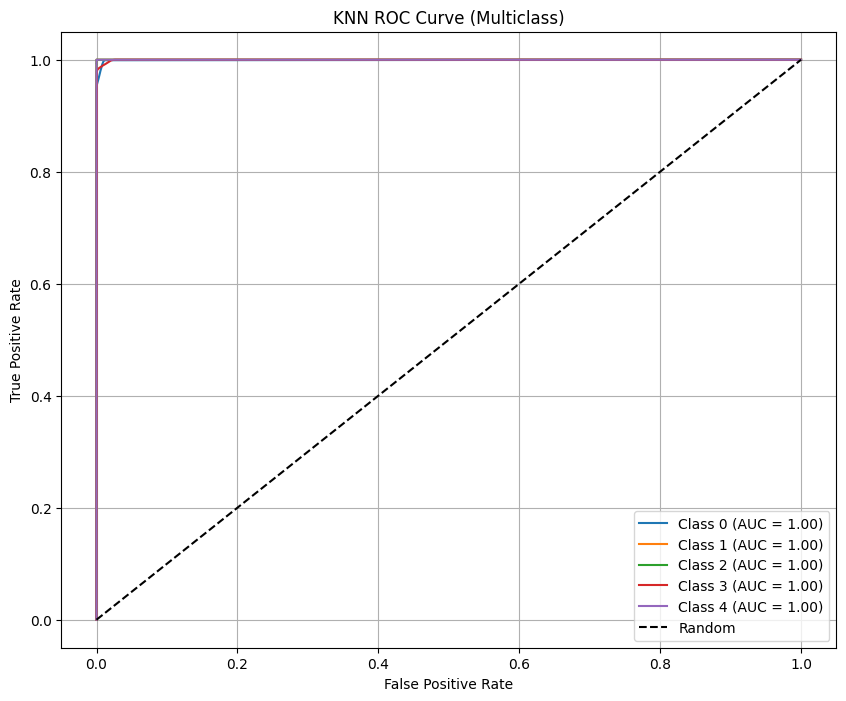

In [28]:
from sklearn.neighbors import KNeighborsClassifier

# Define number of classes (if not defined earlier)
n_classes = len(np.unique(y_train_balanced))

# Binarize test labels for ROC curve
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))

# Manually specified KNN model
knn = KNeighborsClassifier(
    n_neighbors=10,
    n_jobs=-1
)

# Train the model
start_train = time.time()
knn.fit(X_train_scaled, y_train_balanced)
train_time = time.time() - start_train

# Predict on test set
start_pred = time.time()
y_pred_knn = knn.predict(X_test_scaled)
pred_time = time.time() - start_pred

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred_knn)
precision = precision_score(y_test, y_pred_knn, average='macro', zero_division=0)
recall = recall_score(y_test, y_pred_knn, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred_knn, average='macro', zero_division=0)

print(f"Training time: {train_time:.4f} seconds")
print(f"Prediction time: {pred_time:.4f} seconds")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1-score (macro): {f1:.4f}")

# ROC Curve for multiclass
y_score_knn = knn.predict_proba(X_test_scaled)
fpr_knn = dict()
tpr_knn = dict()
roc_auc_knn = dict()
for i in range(n_classes):
    fpr_knn[i], tpr_knn[i], _ = roc_curve(y_test_bin[:, i], y_score_knn[:, i])
    roc_auc_knn[i] = auc(fpr_knn[i], tpr_knn[i])

# Plot ROC Curve
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr_knn[i], tpr_knn[i], label=f'Class {i} (AUC = {roc_auc_knn[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('KNN ROC Curve (Multiclass)')
plt.legend()
plt.grid(True)
plt.show()


In [38]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_knn)

benign_class = 0  # change if needed

TN = cm[benign_class, benign_class]
FP = cm[benign_class, :].sum() - TN

FAR = FP / (FP + TN)
print(FAR)


0.019729206963249517


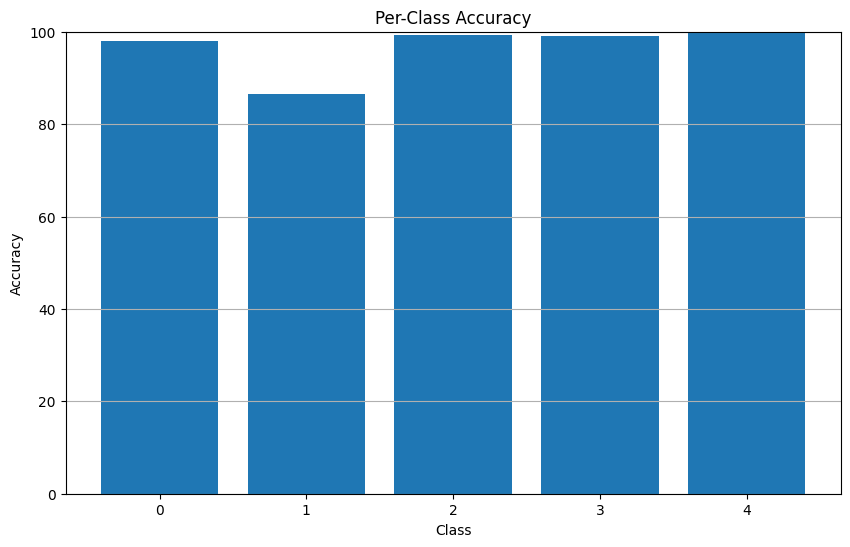

In [29]:
# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_knn, labels=np.arange(n_classes))

# Per-class accuracy: diagonal / row sum
per_class_accuracy = (cm.diagonal() / cm.sum(axis=1) )*100

plt.figure(figsize=(10, 6))
plt.bar(range(n_classes), per_class_accuracy)
plt.xlabel('Class')
plt.ylabel('Accuracy')
plt.title('Per-Class Accuracy')
plt.xticks(range(n_classes))
plt.ylim(0, 100)
plt.grid(axis='y')
plt.show()

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader


Training time: 6625.0316 seconds
Prediction time: 15.9164 seconds
Accuracy: 0.9631
Precision (macro): 0.9605
Recall (macro): 0.8510
F1-score (macro): 0.8860


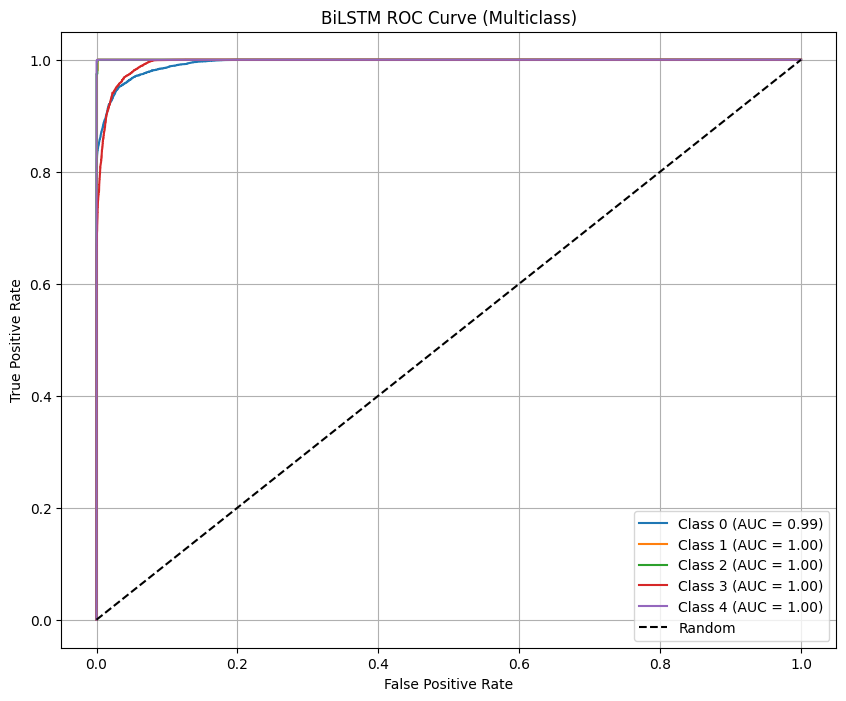

In [30]:
# Set parameters manually
hidden_dim = 256
num_layers = 2
lr = 1e-3
batch_size = 256
epochs = 20

# Prepare data
X_train_seq = torch.tensor(X_train_scaled, dtype=torch.float32).unsqueeze(1)
X_test_seq = torch.tensor(X_test_scaled, dtype=torch.float32).unsqueeze(1)
y_train_tensor = torch.tensor(y_train_balanced, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train_seq, y_train_tensor)
test_dataset = TensorDataset(X_test_seq, y_test_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=False)

# Define BiLSTM model
class BiLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_classes, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers=num_layers, 
                            batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        out = self.fc(out)
        return out

# Initialize model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
input_dim = X_train_scaled.shape[1]
n_classes = len(np.unique(y_train_balanced))
bilstm = BiLSTM(input_dim, hidden_dim, n_classes, num_layers).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(bilstm.parameters(), lr=lr)

# Train the model ONCE
start_train = time.time()
bilstm.train()
for epoch in range(epochs):
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = bilstm(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
train_time = time.time() - start_train

# Evaluate
bilstm.eval()
start_pred = time.time()
all_preds, all_probs = [], []
with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        logits = bilstm(xb)
        probs = torch.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)
        all_preds.append(preds.cpu())
        all_probs.append(probs.cpu())
pred_time = time.time() - start_pred

# Convert predictions
y_pred_bilstm = torch.cat(all_preds).numpy()
y_score_bilstm = torch.cat(all_probs).numpy()

# Metrics
accuracy = accuracy_score(y_test, y_pred_bilstm)
precision = precision_score(y_test, y_pred_bilstm, average='macro', zero_division=0)
recall = recall_score(y_test, y_pred_bilstm, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred_bilstm, average='macro', zero_division=0)

print(f"Training time: {train_time:.4f} seconds")
print(f"Prediction time: {pred_time:.4f} seconds")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1-score (macro): {f1:.4f}")

# ROC Curve
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))
fpr_bilstm = dict()
tpr_bilstm = dict()
roc_auc_bilstm = dict()
for i in range(n_classes):
    fpr_bilstm[i], tpr_bilstm[i], _ = roc_curve(y_test_bin[:, i], y_score_bilstm[:, i])
    roc_auc_bilstm[i] = auc(fpr_bilstm[i], tpr_bilstm[i])

plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr_bilstm[i], tpr_bilstm[i], label=f'Class {i} (AUC = {roc_auc_bilstm[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('BiLSTM ROC Curve (Multiclass)')
plt.legend()
plt.grid(True)
plt.show()


In [39]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_bilstm)

benign_class = 0  # change if needed

TN = cm[benign_class, benign_class]
FP = cm[benign_class, :].sum() - TN

FAR = FP / (FP + TN)
print(FAR)


0.0625886524822695


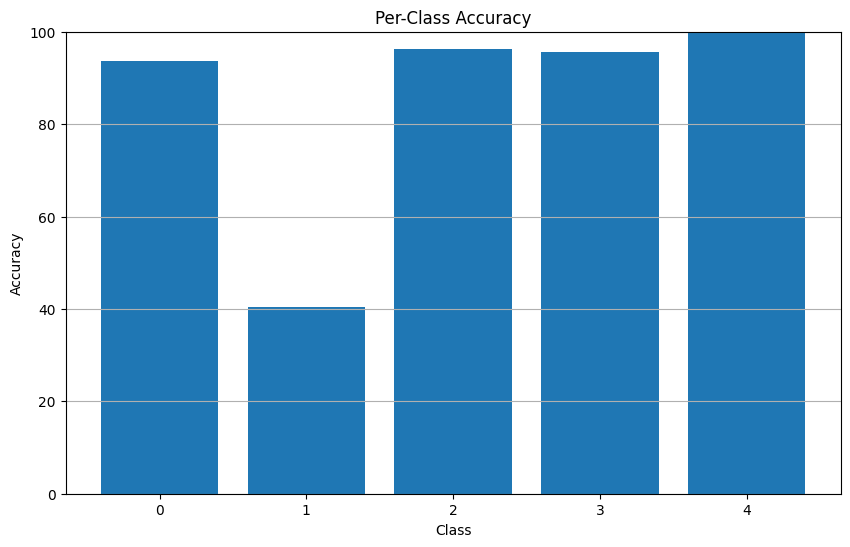

In [31]:
# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_bilstm, labels=np.arange(n_classes))

# Per-class accuracy: diagonal / row sum
per_class_accuracy = (cm.diagonal() / cm.sum(axis=1) )*100

plt.figure(figsize=(10, 6))
plt.bar(range(n_classes), per_class_accuracy)
plt.xlabel('Class')
plt.ylabel('Accuracy')
plt.title('Per-Class Accuracy')
plt.xticks(range(n_classes))
plt.ylim(0, 100)
plt.grid(axis='y')
plt.show()

Training time: 539.5163 seconds
Prediction time: 3.0655 seconds
Accuracy: 0.9613
Precision (macro): 0.9520
Recall (macro): 0.8495
F1-score (macro): 0.8833


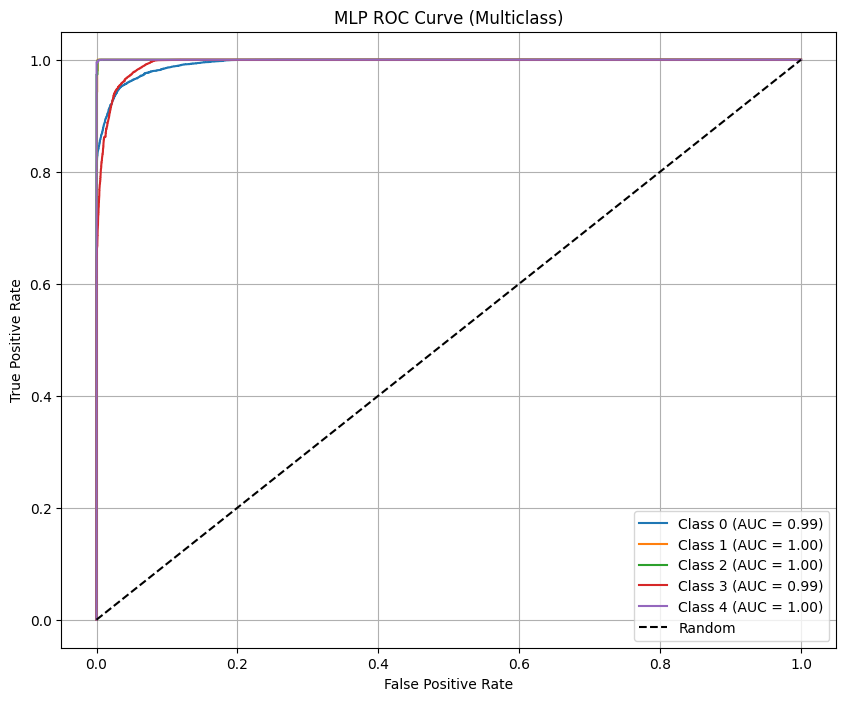

In [32]:
hidden_dim1 = 256
hidden_dim2 = 128
lr = 1e-3  # or 5e-4
batch_size = 256
epochs = 20
n_classes = len(np.unique(y_train_balanced))

# Prepare data
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_balanced, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=False)

# Define MLP model
class TunedMLP(nn.Module):
    def __init__(self, input_dim, num_classes, h1, h2):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, h1),
            nn.ReLU(),
            nn.Linear(h1, h2),
            nn.ReLU(),
            nn.Linear(h2, num_classes)
        )
    def forward(self, x):
        return self.model(x)

# Initialize model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mlp = TunedMLP(X_train_scaled.shape[1], n_classes, hidden_dim1, hidden_dim2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(mlp.parameters(), lr=lr)

# Train the model once
start_train = time.time()
mlp.train()
for epoch in range(epochs):
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = mlp(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
train_time = time.time() - start_train

# Prediction
mlp.eval()
start_pred = time.time()
all_preds, all_probs = [], []
with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        logits = mlp(xb)
        probs = torch.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)
        all_preds.append(preds.cpu())
        all_probs.append(probs.cpu())
pred_time = time.time() - start_pred

# Convert outputs
y_pred_mlp = torch.cat(all_preds).numpy()
y_score_mlp = torch.cat(all_probs).numpy()

# Metrics
accuracy = accuracy_score(y_test, y_pred_mlp)
precision = precision_score(y_test, y_pred_mlp, average='macro', zero_division=0)
recall = recall_score(y_test, y_pred_mlp, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred_mlp, average='macro', zero_division=0)

print(f"Training time: {train_time:.4f} seconds")
print(f"Prediction time: {pred_time:.4f} seconds")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1-score (macro): {f1:.4f}")

# ROC Curve for Multiclass
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))
fpr_mlp = dict()
tpr_mlp = dict()
roc_auc_mlp = dict()
for i in range(n_classes):
    fpr_mlp[i], tpr_mlp[i], _ = roc_curve(y_test_bin[:, i], y_score_mlp[:, i])
    roc_auc_mlp[i] = auc(fpr_mlp[i], tpr_mlp[i])

# Plot ROC Curve
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr_mlp[i], tpr_mlp[i], label=f'Class {i} (AUC = {roc_auc_mlp[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('MLP ROC Curve (Multiclass)')
plt.legend()
plt.grid(True)
plt.show()


In [40]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_mlp)

benign_class = 0  # change if needed

TN = cm[benign_class, benign_class]
FP = cm[benign_class, :].sum() - TN

FAR = FP / (FP + TN)
print(FAR)


0.06794003868471954


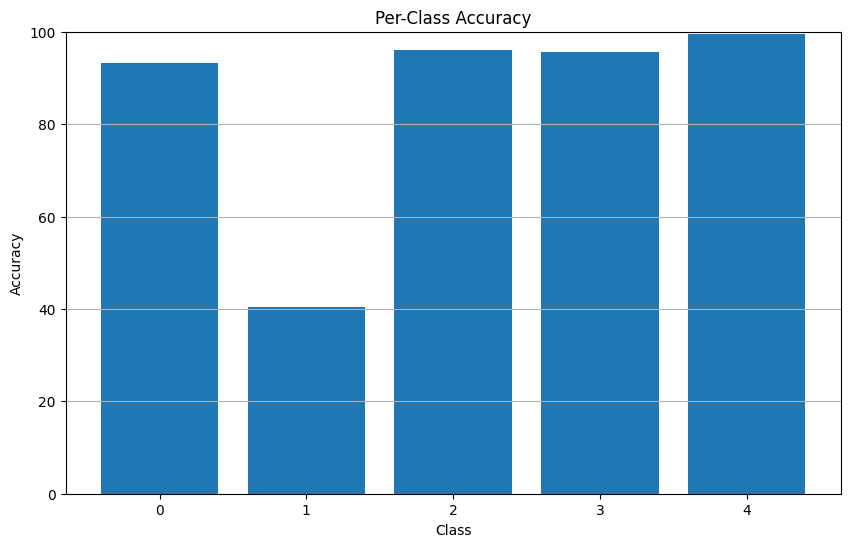

In [33]:
# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_mlp, labels=np.arange(n_classes))

# Per-class accuracy: diagonal / row sum
per_class_accuracy = (cm.diagonal() / cm.sum(axis=1) )*100

plt.figure(figsize=(10, 6))
plt.bar(range(n_classes), per_class_accuracy)
plt.xlabel('Class')
plt.ylabel('Accuracy')
plt.title('Per-Class Accuracy')
plt.xticks(range(n_classes))
plt.ylim(0, 100)
plt.grid(axis='y')
plt.show()

Training time: 470.7152 seconds
Prediction time: 3.0573 seconds
Accuracy: 0.9634
Precision (macro): 0.9609
Recall (macro): 0.8508
F1-score (macro): 0.8861


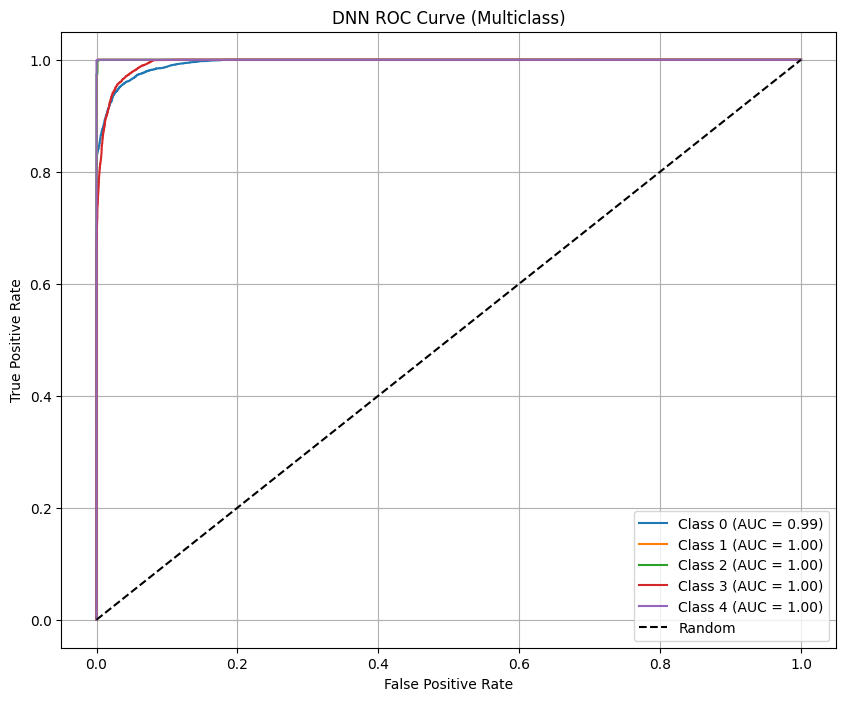

In [34]:
hidden_dim1 = 512
hidden_dim2 = 256
lr = 1e-3
batch_size = 512
epochs = 20
n_classes = len(np.unique(y_train_balanced))

# Prepare data
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_balanced, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=False)

# Define DNN model
class TunedDNN(nn.Module):
    def __init__(self, input_dim, num_classes, h1, h2):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, h1),
            nn.ReLU(),
            nn.BatchNorm1d(h1),
            nn.Linear(h1, h2),
            nn.ReLU(),
            nn.BatchNorm1d(h2),
            nn.Linear(h2, num_classes)
        )
    def forward(self, x):
        return self.model(x)

# Initialize model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dnn = TunedDNN(X_train_scaled.shape[1], n_classes, hidden_dim1, hidden_dim2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(dnn.parameters(), lr=lr)

# Training
start_train = time.time()
dnn.train()
for epoch in range(epochs):
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = dnn(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
train_time = time.time() - start_train

# Prediction
dnn.eval()
start_pred = time.time()
all_preds, all_probs = [], []
with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        logits = dnn(xb)
        probs = torch.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)
        all_preds.append(preds.cpu())
        all_probs.append(probs.cpu())
pred_time = time.time() - start_pred

# Convert outputs
y_pred_dnn = torch.cat(all_preds).numpy()
y_score_dnn = torch.cat(all_probs).numpy()

# Metrics
accuracy = accuracy_score(y_test, y_pred_dnn)
precision = precision_score(y_test, y_pred_dnn, average='macro', zero_division=0)
recall = recall_score(y_test, y_pred_dnn, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred_dnn, average='macro', zero_division=0)

print(f"Training time: {train_time:.4f} seconds")
print(f"Prediction time: {pred_time:.4f} seconds")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1-score (macro): {f1:.4f}")

# ROC Curve for Multiclass
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))
fpr_dnn = dict()
tpr_dnn = dict()
roc_auc_dnn = dict()
for i in range(n_classes):
    fpr_dnn[i], tpr_dnn[i], _ = roc_curve(y_test_bin[:, i], y_score_dnn[:, i])
    roc_auc_dnn[i] = auc(fpr_dnn[i], tpr_dnn[i])

# Plot ROC
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr_dnn[i], tpr_dnn[i], label=f'Class {i} (AUC = {roc_auc_dnn[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('DNN ROC Curve (Multiclass)')
plt.legend()
plt.grid(True)
plt.show()


In [41]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_dnn)

benign_class = 0  # change if needed

TN = cm[benign_class, benign_class]
FP = cm[benign_class, :].sum() - TN

FAR = FP / (FP + TN)
print(FAR)


0.07190522243713733


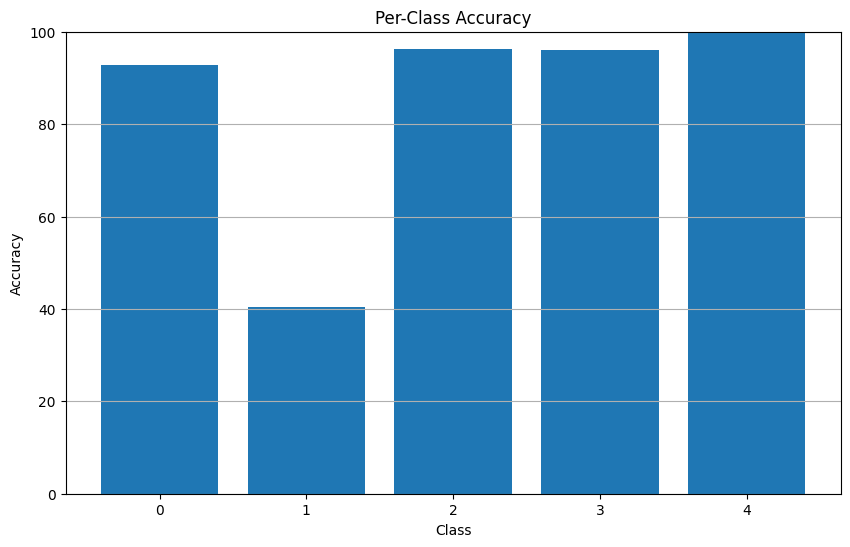

In [35]:
# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_dnn, labels=np.arange(n_classes))

# Per-class accuracy: diagonal / row sum
per_class_accuracy = (cm.diagonal() / cm.sum(axis=1) )*100

plt.figure(figsize=(10, 6))
plt.bar(range(n_classes), per_class_accuracy)
plt.xlabel('Class')
plt.ylabel('Accuracy')
plt.title('Per-Class Accuracy')
plt.xticks(range(n_classes))
plt.ylim(0, 100)
plt.grid(axis='y')
plt.show()

In [34]:
import shap

explainer =shap.Explainer(dt)

shap_values=explainer(X_test_scaled)

In [35]:
np.shape(shap_values.values)

(217708, 6, 5)

In [37]:
import shap
shap.initjs()


In [42]:
shap.plots.force(
    shap_values[0, :, 0]   # sample 0, all features, class 0
)

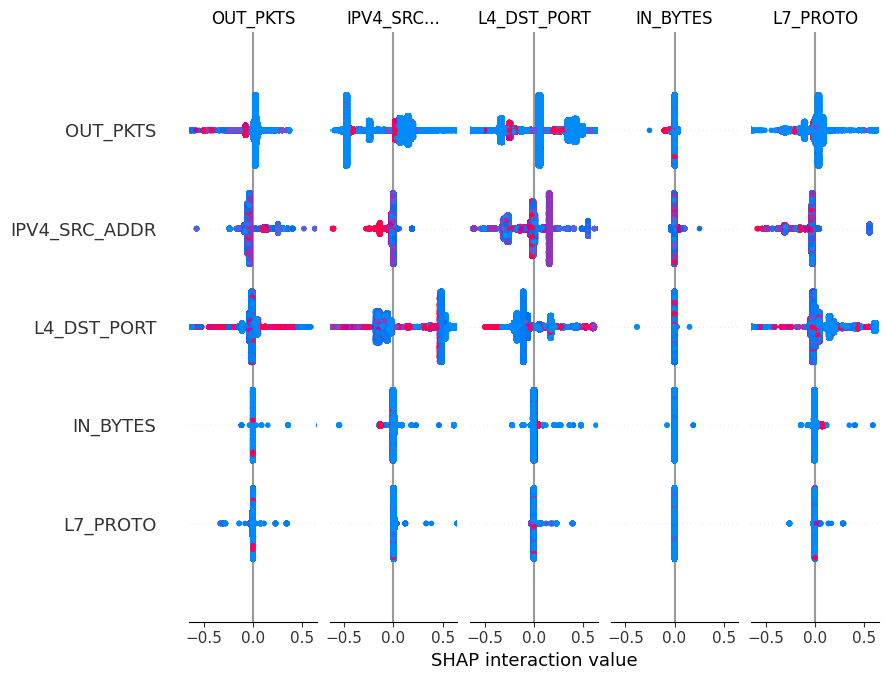

In [36]:
import shap

# Create a TreeExplainer for the trained Decision Tree model
explainer = shap.TreeExplainer(dt)

# Compute SHAP values for the test set
shap_values = explainer.shap_values(X_test_scaled)

# Plot summary for all classes (multiclass)
shap.summary_plot(shap_values, X_test_scaled, feature_names=df.drop('label', axis=1).columns)

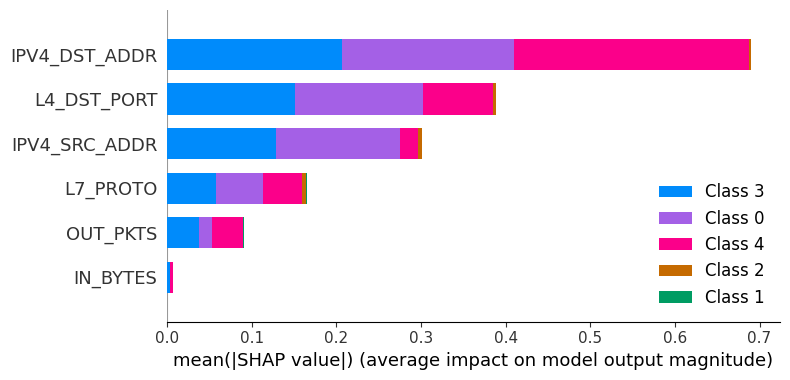

In [37]:
shap.summary_plot(
    shap_values, 
    X_test_scaled, 
    feature_names=df.drop('label', axis=1).columns,
    plot_type="bar"
)

In [38]:
import lime
import lime.lime_tabular
from IPython.core.display import display, HTML
import pandas as pd
import numpy as np

# Create LIME explainer
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    X_train_scaled,
    feature_names=df.drop('label', axis=1).columns,
    class_names=[str(i) for i in range(len(np.unique(y_train_balanced)))],
    discretize_continuous=True,
    mode='classification'
)

# Explain one instance
i = 0
# Request explanation for all class labels seen in training
all_class_labels = list(range(len(np.unique(y_train_balanced))))
exp = explainer_lime.explain_instance(
    X_test_scaled[i],
    dt.predict_proba,
    num_features=10,
    labels=all_class_labels
)

# Styling for table cells
def color_weight(val):
    if val > 0:
        return 'background-color: #a5d6a7; color: black;'
    else:
        return 'background-color: #ef9a9a; color: black;'

# CSS for light mode HTML rendering
style_block = """
<style>
body {
    background-color: #ffffff !important;
    color: #000000 !important;
    font-family: "Segoe UI", sans-serif !important;
}
table, th, td {
    background-color: #f5f5f5 !important;
    color: #000000 !important;
    border: 1px solid #ccc !important;
}
.positive {
    background-color: #a5d6a7 !important;
    color: #000000 !important;
}
.negative {
    background-color: #ef9a9a !important;
    color: #000000 !important;
}
</style>
"""

# Only show available explanations (LIME may skip some classes)
for class_idx in exp.available_labels():
    # ---- Table ----
    df_exp = pd.DataFrame(exp.as_list(label=class_idx), columns=["Feature", "Weight"])
    styled_table = df_exp.style.applymap(color_weight, subset=["Weight"]) \
                               .set_properties(**{
                                   'background-color': '#ffffff',
                                   'color': 'black',
                                   'border-color': '#ccc'
                               })

    display(HTML(f"<h3 style='color:black;'>LIME Table for Class {class_idx}</h3>"))
    display(styled_table)

    # ---- Chart ----
    exp.top_labels = [class_idx]  # Set to show this class
    html = exp.as_html()
    html = html.replace("</head>", style_block + "</head>")

    display(HTML(f"<h3 style='color:black;'>LIME Chart for Class {class_idx}</h3>"))
    display(HTML(html))


C:\Users\krish\AppData\Local\Temp\ipykernel_19736\2032506395.py:3: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython.display
  from IPython.core.display import display, HTML
C:\Users\krish\AppData\Local\Temp\ipykernel_19736\2032506395.py:62: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled_table = df_exp.style.applymap(color_weight, subset=["Weight"]) \


,Feature,Weight
0,IPV4_DST_ADDR <= -0.37,0.545362
1,-0.27 < IPV4_SRC_ADDR <= 0.37,0.462255
2,L7_PROTO <= -0.31,0.070709
3,IN_BYTES <= -0.07,0.017727
4,OUT_PKTS <= -0.08,0.006334
5,-0.58 < L4_DST_PORT <= -0.27,0.005831


C:\Users\krish\AppData\Local\Temp\ipykernel_19736\2032506395.py:62: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled_table = df_exp.style.applymap(color_weight, subset=["Weight"]) \


,Feature,Weight
0,-0.58 < L4_DST_PORT <= -0.27,-0.048513
1,IPV4_DST_ADDR <= -0.37,-0.033262
2,-0.27 < IPV4_SRC_ADDR <= 0.37,-0.032908
3,L7_PROTO <= -0.31,0.011088
4,IN_BYTES <= -0.07,-0.005418
5,OUT_PKTS <= -0.08,-0.001578


C:\Users\krish\AppData\Local\Temp\ipykernel_19736\2032506395.py:62: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled_table = df_exp.style.applymap(color_weight, subset=["Weight"]) \


,Feature,Weight
0,-0.58 < L4_DST_PORT <= -0.27,-0.015994
1,IPV4_DST_ADDR <= -0.37,-0.012110
2,-0.27 < IPV4_SRC_ADDR <= 0.37,-0.011341
3,L7_PROTO <= -0.31,0.007263
4,OUT_PKTS <= -0.08,-0.003421
5,IN_BYTES <= -0.07,0.000173


C:\Users\krish\AppData\Local\Temp\ipykernel_19736\2032506395.py:62: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled_table = df_exp.style.applymap(color_weight, subset=["Weight"]) \


,Feature,Weight
0,IPV4_DST_ADDR <= -0.37,-0.390417
1,-0.27 < IPV4_SRC_ADDR <= 0.37,-0.319627
2,-0.58 < L4_DST_PORT <= -0.27,0.203999
3,L7_PROTO <= -0.31,-0.095706
4,OUT_PKTS <= -0.08,0.012475
5,IN_BYTES <= -0.07,-0.000224


C:\Users\krish\AppData\Local\Temp\ipykernel_19736\2032506395.py:62: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled_table = df_exp.style.applymap(color_weight, subset=["Weight"]) \


,Feature,Weight
0,-0.58 < L4_DST_PORT <= -0.27,-0.145325
1,IPV4_DST_ADDR <= -0.37,-0.109572
2,-0.27 < IPV4_SRC_ADDR <= 0.37,-0.098379
3,OUT_PKTS <= -0.08,-0.013809
4,IN_BYTES <= -0.07,-0.012258
5,L7_PROTO <= -0.31,0.006645


LIME explanation for class 0 (test sample index 4):


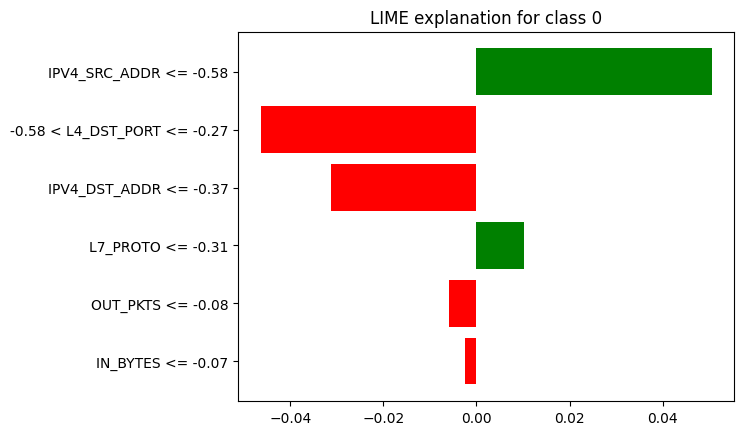

LIME explanation for class 1 (test sample index 2613):


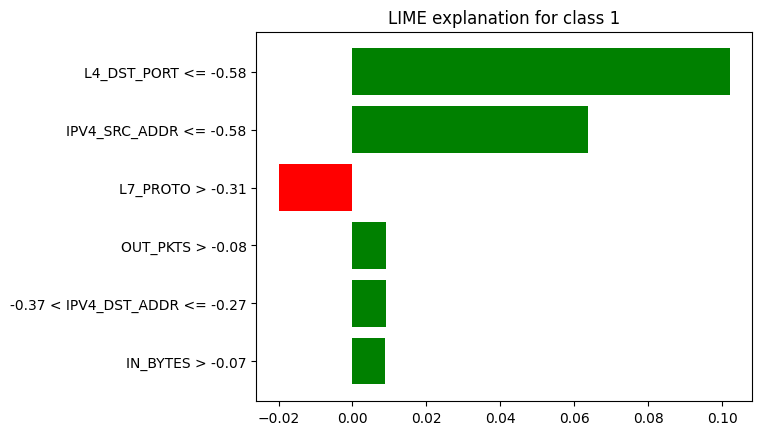

LIME explanation for class 2 (test sample index 5):


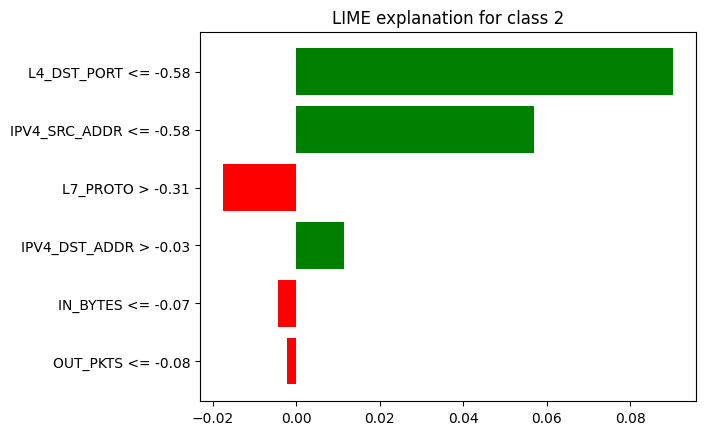

LIME explanation for class 3 (test sample index 1):


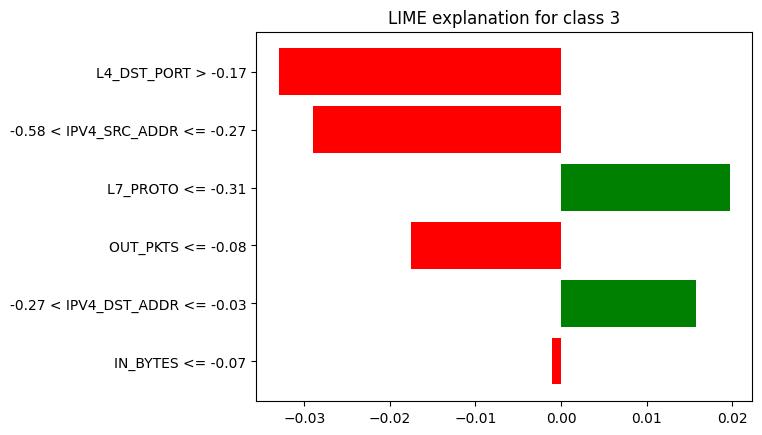

LIME explanation for class 4 (test sample index 0):


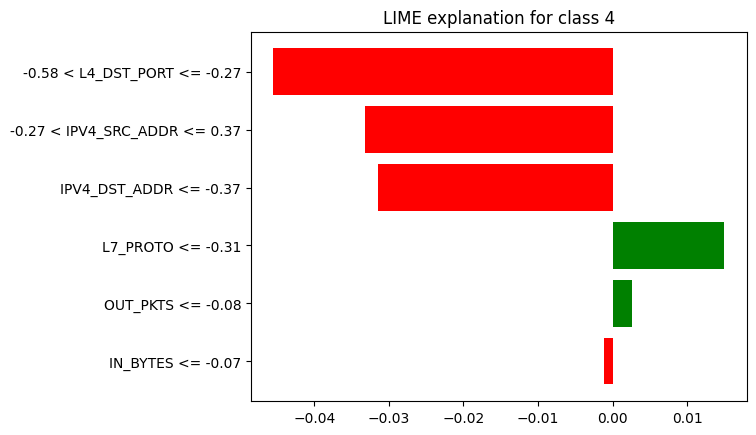

In [39]:
# Loop through each class and plot LIME explanation for the first test sample of each class
for class_idx in range(len(np.unique(y_test))):
    # Find the first index of this class in the test set
    idx = np.where(y_test == class_idx)[0]
    if len(idx) == 0:
        continue  # skip if class not present in y_test
    i = idx[0]
    exp = explainer_lime.explain_instance(
        X_test_scaled[i],
        dt.predict_proba,
        num_features=10
    )
    print(f"LIME explanation for class {class_idx} (test sample index {i}):")
    fig = exp.as_pyplot_figure()
    plt.title(f"LIME explanation for class {class_idx}")
    plt.show()

c:\Users\krish\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\krish\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\krish\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\krish\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\krish\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without featur

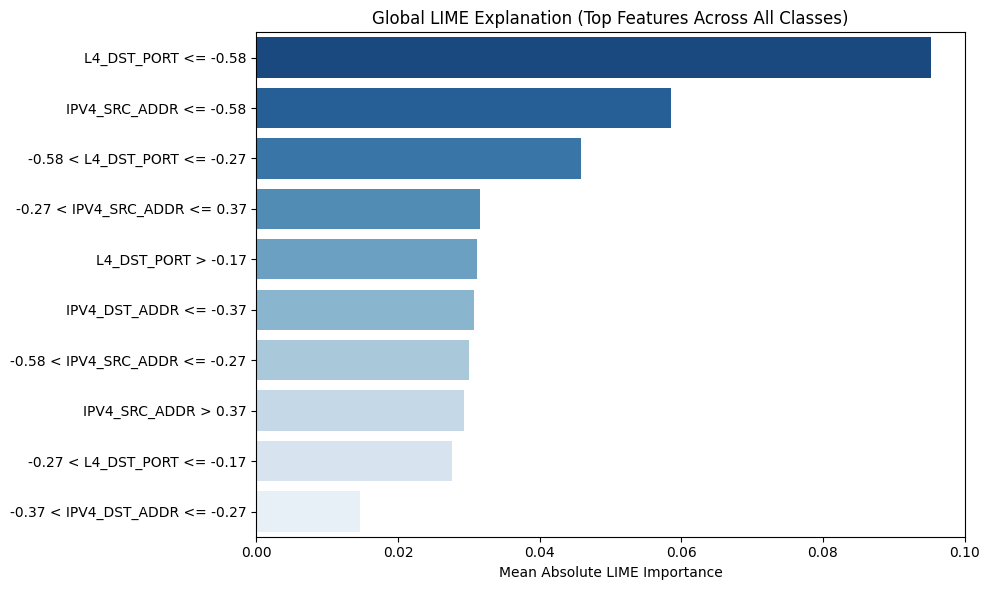

In [40]:
from collections import defaultdict

# LIME explainer
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_scaled,
    feature_names=df.drop('label', axis=1).columns.tolist(),
    class_names=[str(i) for i in range(len(np.unique(y_train)))],
    mode='classification',
    discretize_continuous=True
)

# Prediction wrapper
def predict_proba_with_names(X):
    if len(X.shape) == 1:
        X = X.reshape(1, -1)
    X_df = pd.DataFrame(X, columns=df.drop('label', axis=1).columns)
    return dt.predict_proba(X_df)

# Parameters
num_features = 10
max_samples = 100  # Adjust as needed

# Store total absolute importance for each feature
feature_importance_total = defaultdict(float)
feature_counts = defaultdict(int)

# Loop over test samples and collect feature importances
for i in range(min(len(X_test_scaled), max_samples)):
    exp = explainer_lime.explain_instance(
        X_test_scaled[i],
        predict_proba_with_names,
        num_features=num_features,
        top_labels=None
    )

    for label in exp.available_labels():
        for feature, weight in exp.as_list(label=label):
            feature_importance_total[feature] += abs(weight)
            feature_counts[feature] += 1

# Compute mean absolute importance
feature_importance_avg = {
    feat: feature_importance_total[feat] / feature_counts[feat]
    for feat in feature_importance_total
}

# Convert to DataFrame
importance_df = pd.DataFrame({
    'Feature': list(feature_importance_avg.keys()),
    'Mean_Absolute_Importance': list(feature_importance_avg.values())
})

# Sort by importance
importance_df = importance_df.sort_values(by='Mean_Absolute_Importance', ascending=False)

# Plot like your image
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df.head(10),
    x='Mean_Absolute_Importance',
    y='Feature',
    palette='Blues_r'
)
plt.title("Global LIME Explanation (Top Features Across All Classes)")
plt.xlabel("Mean Absolute LIME Importance")
plt.ylabel("")
plt.tight_layout()
plt.show()
